# Part 1: Model Selection and Architecture Tuning

Part 1 investigates convolutional neural network (CNN) architectures for a 10-class bird-image classification task. A two-stage search is employed: candidate architectures are initially screened using images resized to 128 × 128 pixels, after which selected candidates are trained and evaluated at the final resolution of 224 × 224 pixels. This procedure reduces the computational cost of the initial search while enabling final model selection at the resolution used in the subsequent experiments.


In [3]:
from pathlib import Path
import json

import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_images
from PIL import Image
import keras
import numpy as np
from collections import Counter

import keras_tuner as kt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


# Utility functions for saving and reloading model histories so that tuning runs can be
# resumed without re-training every candidate from scratch when the notebook is rerun.
def save_history(history, path):
    with open(path, "w") as f:
        json.dump(history.history, f)


def load_history(path):
    with open(path, "r") as f:
        loaded = json.load(f)
    history = tf.keras.callbacks.History()
    history.history = loaded

    return history

In [4]:
# All file paths are resolved relative to the notebook directory so that model checkpoints,
# training histories, and saved configurations remain consistent across reruns.
NOTEBOOK_DIR = Path.cwd()
P1_TRAIN_DIR = NOTEBOOK_DIR / "part1_train"
P1_VALID_DIR = NOTEBOOK_DIR / "part1_valid"
P1_TEST_DIR = NOTEBOOK_DIR / "part1_test"
P2_TRAIN_DIR = NOTEBOOK_DIR / "part2_train"
P2_VALID_DIR = NOTEBOOK_DIR / "part2_valid"
P2_TEST_DIR = NOTEBOOK_DIR / "part2_test"
CNN_A_MODEL_PATH = NOTEBOOK_DIR / "CNN_A.keras"
CNN_B_MODEL_PATH = NOTEBOOK_DIR / "CNN_B.keras"
ARTIFACTS_DIR = NOTEBOOK_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

print(f"Base model exists: {CNN_A_MODEL_PATH.exists()}")
print(f"Train directory exists: {P1_TRAIN_DIR.exists()}")
print(f"Validation directory exists: {P1_VALID_DIR.exists()}")
print(f"Test directory exists: {P1_TEST_DIR.exists()}")
print(f"Train directory exists: {P2_TRAIN_DIR.exists()}")
print(f"Validation directory exists: {P2_VALID_DIR.exists()}")
print(f"Test directory exists: {P2_TEST_DIR.exists()}")

# Force CPU before tuner/model creation to avoid Metal GPU timeout errors on macOS.
tf.keras.backend.clear_session()
try:
    tf.config.list_physical_devices("GPU")
    print("Using GPU for model creation and tuning.")
except RuntimeError:
    print("Using CPU for model creation and tuning.")
    pass

plt.rcParams["font.size"] = 14
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["legend.fontsize"] = 12

Base model exists: True
Train directory exists: True
Validation directory exists: True
Test directory exists: True
Train directory exists: True
Validation directory exists: True
Test directory exists: True
Using GPU for model creation and tuning.


### Part 1a: Initial Hyperparameter Tuning

The initial search uses reduced-resolution training and validation images to identify promising CNN configurations. The search space includes network depth, convolutional filter count and kernel size, dense-layer width, and learning rate. Candidates with the strongest validation performance are retained for full-resolution comparison. The test set is excluded from hyperparameter selection.


In [5]:
# import the images for tuning
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
val_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
test_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)

X_train = train_gen.flow_from_directory(
    str(P1_TRAIN_DIR),
    target_size=(128, 128),
    batch_size=32,
)
X_test = test_gen.flow_from_directory(
    str(P1_TEST_DIR), target_size=(128, 128), batch_size=32
)
X_valid = val_gen.flow_from_directory(
    str(P1_VALID_DIR), target_size=(128, 128), batch_size=32
)

Found 1546 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


Text(0.5, 1.0, 'Test Image')

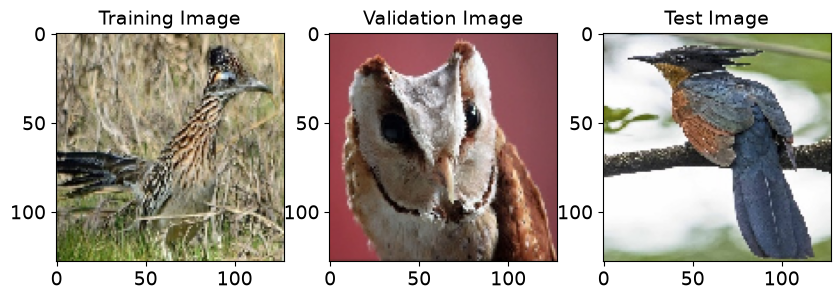

In [6]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train[0][0][0])
plt.title("Training Image")
plt.subplot(1, 3, 2)
plt.imshow(X_valid[0][0][0])
plt.title("Validation Image")
plt.subplot(1, 3, 3)
plt.imshow(X_test[0][0][0])
plt.title("Test Image")

### Search Hyperparameters

The initial search varies the following hyperparameters:

- Number of convolutional blocks: 1–4
- Number of filters: 32, 64, or 128
- Convolutional kernel size: 3 × 3 or 5 × 5
- Number of dense units: 64 or 128
- Learning rate: 0.0001–0.000001

These ranges define the candidate architectures evaluated during screening. Validation performance on the reduced-resolution data is used to identify candidates for subsequent full-resolution evaluation.


In [7]:
# Reduced-resolution architecture search for the first-stage tuning pass.
# This provides a fast screening stage before committing to the more expensive full-size retraining.
def build_candidate_model(hp):
    inputs = tf.keras.Input(shape=(128, 128, 3))
    x = inputs

    # Search over a compact architecture family: block depth, filter size, kernel size,
    # dense layer width, learning rate, and dropout regularisation.
    for i in range(hp.Int("num_blocks", 1, 4)):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu",
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(hp.Choice("dense_units", [64, 128]), activation="relu")(x)
    x = tf.keras.layers.Dropout(hp.Float("dropout", 0.2, 0.5, step=0.1))(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [8]:
# %%time
FAST_TUNER_DIR = NOTEBOOK_DIR / "keras_tuner_results" / "image_classifier_fast"
FAST_MODEL_PATH = NOTEBOOK_DIR / "best_fast_model.keras"
FAST_HP_PATH = NOTEBOOK_DIR / "best_fast_hp.json"

# The fast search is intentionally lightweight: it screens promising architectures on
# reduced images before the most competitive candidates are retrained at the final resolution.
tuner = kt.Hyperband(
    build_candidate_model,
    objective="val_accuracy",
    max_epochs=25,
    factor=3,
    directory="keras_tuner_results",
    project_name="image_classifier_fast",
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

if FAST_MODEL_PATH.exists() and FAST_HP_PATH.exists():
    print("Loading the saved best fast-tuning model from disk...")
    best_model = tf.keras.models.load_model(FAST_MODEL_PATH)
    with open(FAST_HP_PATH, "r") as f:
        best_hp = kt.HyperParameters.from_config(json.load(f))
    tuner.search(X_train, validation_data=(X_valid), callbacks=[early_stopping])
else:
    tuner.search(X_train, validation_data=(X_valid), callbacks=[early_stopping])
    best_model = tuner.get_best_models(num_models=1)[0]
    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    best_model.save(FAST_MODEL_PATH)
    with open(FAST_HP_PATH, "w") as f:
        json.dump(best_hp.get_config(), f)

# If we loaded from disk, keep the tuner object aligned with the saved result.
if not FAST_MODEL_PATH.exists() or not FAST_HP_PATH.exists():
    best_model = tuner.get_best_models(num_models=1)[0]
    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_model.summary())

Reloading Tuner from keras_tuner_results/image_classifier_fast/tuner0.json
Loading the saved best fast-tuning model from disk...


I0000 00:00:1794351618.891833 17312334 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
W0000 00:00:1794351618.892088 17312334 pluggable_device_bfc_allocator.cc:36] Overriding allow_growth setting because force_memory_growth was requested by the device.
I0000 00:00:1794351618.892094 17312334 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 10267 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
W0000 00:00:1794351618.986713 17312334 metal_kernel_util.mm:220] Metal: this TensorFlow does not export the kernel C API for resource variables, so its own kernels update variables from the host. Every Metal kernel now waits for the GPU before returning, which is slower and is the only way those updates cannot race. See https://github.com/tensorflow/tensorflow/issues/126374.
/Users/lauryn/Doc

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 128)    │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,184,704 (4.52 MB)

 Trainable params: 394,666 (1.51 MB)

 Non-trainable params: 704 (2.75 KB)

 Optimizer params: 789,334 (3.01 MB)

None


Loading saved fast candidate 1 from disk...


I0000 00:00:1794351619.285233 17312334 custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Loading saved fast candidate 2 from disk...
Loading saved fast candidate 3 from disk...
   candidate  val_accuracy  val_precision_macro  val_recall_macro  \
0          1          0.94             0.090000              0.10   
1          2          0.78             0.115238              0.12   
2          3          0.74             0.104722              0.12   

   val_f1_macro  
0      0.094545  
1      0.115960  
2      0.108400  
Top 3 fast-model validation accuracies:
Candidate 1: 0.9400
Candidate 2: 0.7800
Candidate 3: 0.7400


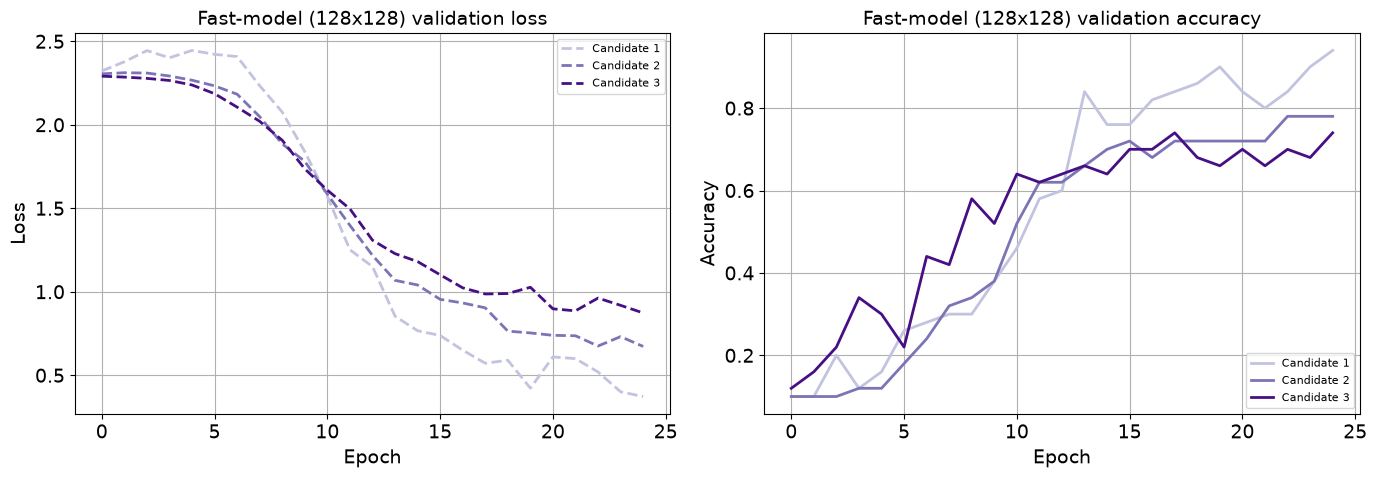

In [9]:
# Plot the fast tuning results (128x128)
fast_histories = []
trial_scores = []
fast_candidate_metrics = []
FAST_TUNING_DIR = NOTEBOOK_DIR / "fast_tuning_candidates"
FAST_TUNING_DIR.mkdir(exist_ok=True)

# Rebuild and train the top 3 fast models to collect learning curves
for i, hp in enumerate(tuner.get_best_hyperparameters(num_trials=3), 1):
    model_path = FAST_TUNING_DIR / f"fast_candidate_{i}.keras"
    history_path = FAST_TUNING_DIR / f"fast_candidate_{i}_history.json"

    if model_path.exists() and history_path.exists():
        print(f"Loading saved fast candidate {i} from disk...")
        model = tf.keras.models.load_model(model_path)
        history = load_history(history_path)
    else:
        print(f"Training fast candidate {i}...")
        model = build_candidate_model(hp)
        history = model.fit(
            X_train,
            validation_data=X_valid,
            epochs=25,
            callbacks=[early_stopping],
            verbose=0,
        )
        model.save(model_path)
        save_history(history, history_path)

    fast_histories.append(history)
    trial_scores.append((i, max(history.history["val_accuracy"])))

    y_true = X_valid.classes
    y_pred = np.argmax(model.predict(X_valid, verbose=0), axis=1)
    fast_candidate_metrics.append(
        {
            "candidate": i,
            "val_accuracy": max(history.history["val_accuracy"]),
            "val_precision_macro": precision_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "val_recall_macro": recall_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "val_f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        }
    )

print(
    pd.DataFrame(fast_candidate_metrics)[
        [
            "candidate",
            "val_accuracy",
            "val_precision_macro",
            "val_recall_macro",
            "val_f1_macro",
        ]
    ]
)
print("Top 3 fast-model validation accuracies:")
for i, score in trial_scores:
    print(f"Candidate {i}: {score:.4f}")

# Show validation loss and accuracy side by side for each candidate.
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(fast_histories)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, history in enumerate(fast_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    axes[0].plot(
        epochs,
        history.history["val_loss"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
        linestyle="--",
    )
    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
    )

axes[0].set_title("Fast-model (128x128) validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].grid(True)

axes[1].set_title("Fast-model (128x128) validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(True)

fig.tight_layout()
fig.savefig(
    ARTIFACTS_DIR / "fast_model_validation_metrics.png", dpi=150, bbox_inches="tight"
)
plt.show()

In [10]:
# Optional: print the top 5 tuned configurations for reporting
best_hps = tuner.get_best_hyperparameters(num_trials=5)

hp_rows = []
for i, hp in enumerate(best_hps, 1):
    row = {"candidate": i}
    row.update(hp.values)
    hp_rows.append(row)

hp_df = pd.DataFrame(hp_rows)
hp_df

,candidate,num_blocks,filters_0,kernel_0,dense_units,dropout,learning_rate,filters_1,kernel_1,filters_2,kernel_2,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,filters_3,kernel_3,tuner/trial_id
0,1,4,64,3,64,0.4,0.000160,128,5,128,3,25,9,1,1,32.0,3.0,0021
1,2,3,64,3,128,0.4,0.000094,32,3,64,5,25,0,0,0,32.0,3.0,NaN
2,3,2,128,3,64,0.4,0.000065,128,5,128,3,25,0,0,0,64.0,3.0,NaN
3,4,2,64,5,64,0.3,0.000276,64,5,64,5,25,9,1,1,128.0,5.0,0018
4,5,1,128,3,128,0.2,0.000729,32,3,32,3,25,9,2,2,NaN,NaN,0012


### Interpretation of the Initial Search

The 128 × 128 search is used for candidate screening and does not provide the final estimate of model performance. Image resolution affects the spatial information available to the network and may influence the convergence behaviour and relative performance of different architectures. Consequently, rankings obtained during reduced-resolution training may not be preserved at 224 × 224 pixels. Final architecture selection is therefore based on validation performance from the full-resolution runs; test performance is reported only after selection.


## Part 1b: Focused Hyperparameter Tuning

The strongest candidates from the initial search are retrained at 224 × 224 pixels and compared using the designated data splits. A focused search is also conducted for four-block architectures, as deeper models may require a longer training schedule than that used in the initial search. Validation accuracy is used to identify candidates for final comparison, and the held-out test set is used for final evaluation.


In [11]:
# Load the full-size images for the final model comparison
train_full = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest",
)

val_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
test_full = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)

X_train_full = train_full.flow_from_directory(
    str(P1_TRAIN_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True,
)

X_test_full = test_full.flow_from_directory(
    str(P1_TEST_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False,
)

X_valid_full = val_full.flow_from_directory(
    str(P1_VALID_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False,
)

Found 1546 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


### Handling Class Imbalance

The training split exhibits variation in the number of images per class, whereas the validation and test splits contain five images per class. Class weights are calculated from the training-set frequencies and supplied during model fitting. This weighting scheme increases the contribution of less frequent classes to the training loss without duplicating samples or altering the validation and test distributions.


In [12]:
# Check whether the class distribution is balanced across the dataset.

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [
    ("train", P1_TRAIN_DIR),
    ("valid", P1_VALID_DIR),
    ("test", P1_TEST_DIR),
]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob("*")))
            if split_name == "train":
                train_counts[class_dir.name] = count
            elif split_name == "valid":
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print("Train class counts:", dict(train_counts))
print("Validation class counts:", dict(valid_counts))
print("Test class counts:", dict(test_counts))

train_balanced = len(set(train_counts.values())) == 1
valid_balanced = len(set(valid_counts.values())) == 1
test_balanced = len(set(test_counts.values())) == 1

print(f"Train balanced: {train_balanced}")
print(f"Validation balanced: {valid_balanced}")
print(f"Test balanced: {test_balanced}")

# Compute a class-weight dictionary based on the imbalanced training split.
# This down-weights majority classes without duplicating images or altering the
# original dataset distribution.
class_indices = X_train_full.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)

for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print("Class weights:", class_weights)

Train class counts: {'BROWN THRASHER': 163, 'CHESTNUT WINGED CUCKOO': 170, 'CUBAN TODY': 162, 'EGYPTIAN GOOSE': 157, 'FIERY MINIVET': 150, 'HOOPOES': 155, 'ORANGE BRESTED BUNTING': 132, 'ORIENTAL BAY OWL': 157, 'RAINBOW LORIKEET': 140, 'ROADRUNNER': 160}
Validation class counts: {'BROWN THRASHER': 5, 'CHESTNUT WINGED CUCKOO': 5, 'CUBAN TODY': 5, 'EGYPTIAN GOOSE': 5, 'FIERY MINIVET': 5, 'HOOPOES': 5, 'ORANGE BRESTED BUNTING': 5, 'ORIENTAL BAY OWL': 5, 'RAINBOW LORIKEET': 5, 'ROADRUNNER': 5}
Test class counts: {'BROWN THRASHER': 5, 'CHESTNUT WINGED CUCKOO': 5, 'CUBAN TODY': 5, 'EGYPTIAN GOOSE': 5, 'FIERY MINIVET': 5, 'HOOPOES': 5, 'ORANGE BRESTED BUNTING': 5, 'ORIENTAL BAY OWL': 5, 'RAINBOW LORIKEET': 5, 'ROADRUNNER': 5}
Train balanced: False
Validation balanced: True
Test balanced: True
Class weights: {0: 0.9484662576687116, 1: 0.9094117647058824, 2: 0.9543209876543209, 3: 0.9847133757961783, 4: 1.0306666666666666, 5: 0.9974193548387097, 6: 1.1712121212121211, 7: 0.9847133757961783, 8: 

Text(0.5, 1.0, 'Test Image')

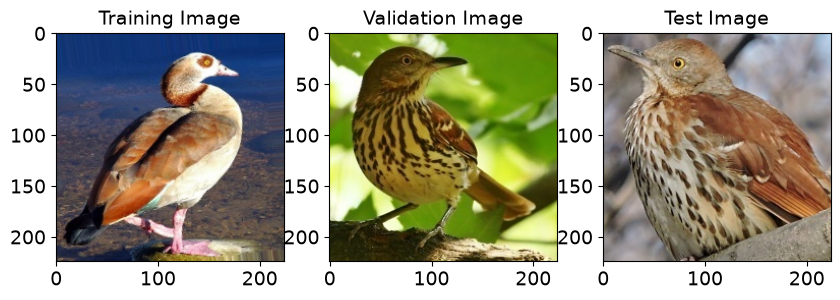

In [13]:
# display the first image in each set
plt.figure(figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(X_train_full[0][0][0])
plt.title("Training Image")
plt.subplot(1, 3, 2)
plt.imshow(X_valid_full[0][0][0])
plt.title("Validation Image")
plt.subplot(1, 3, 3)
plt.imshow(X_test_full[0][0][0])
plt.title("Test Image")


Training candidate 1 on full-size data...
Loading saved full-size model candidate 1 from disk...
Candidate 1 loaded or trained. Validation accuracy: 0.9600

Training candidate 2 on full-size data...
Loading saved full-size model candidate 2 from disk...
Candidate 2 loaded or trained. Validation accuracy: 0.8800

Training candidate 3 on full-size data...
Loading saved full-size model candidate 3 from disk...
Candidate 3 loaded or trained. Validation accuracy: 0.8400


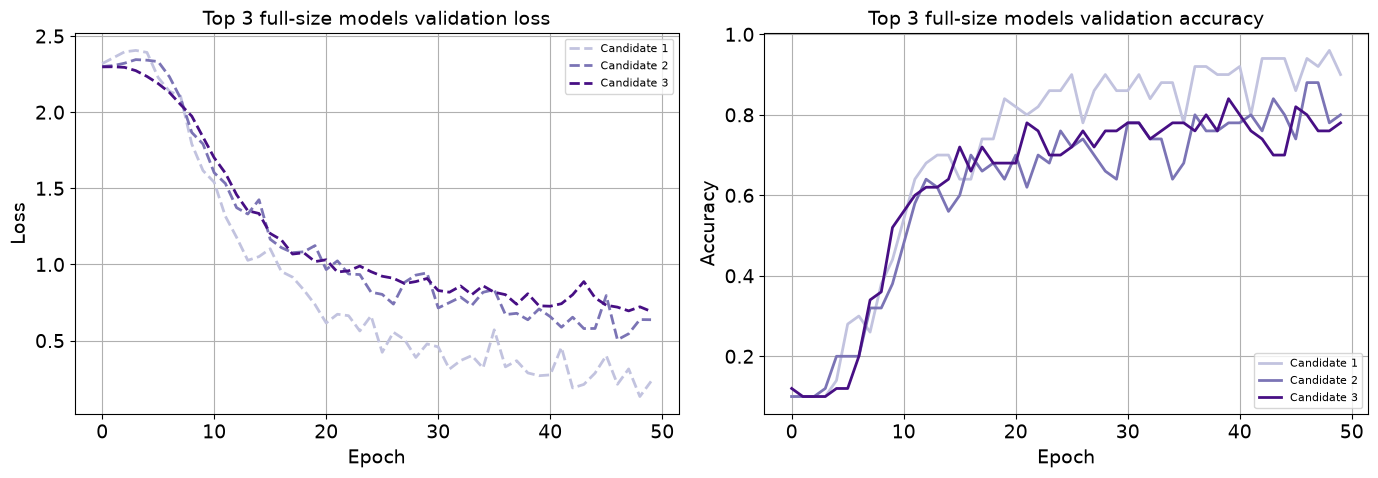

In [14]:
top_hps = tuner.get_best_hyperparameters(3)
all_histories = []
results = []
trained_full_models = []
FULL_TUNING_DIR = NOTEBOOK_DIR / "full_tuning_candidates"
FULL_TUNING_DIR.mkdir(exist_ok=True)

for i, hp in enumerate(top_hps, 1):
    print(f"\nTraining candidate {i} on full-size data...")
    model_path = FULL_TUNING_DIR / f"candidate_full_{i}.keras"
    history_path = FULL_TUNING_DIR / f"candidate_full_{i}_history.json"

    def build_candidate_model_full():
        inputs = tf.keras.Input(shape=(224, 224, 3))
        x = inputs

        for j in range(hp.get("num_blocks")):
            x = tf.keras.layers.Conv2D(
                hp.get(f"filters_{j}"),
                kernel_size=hp.get(f"kernel_{j}"),
                padding="same",
                activation="relu",
            )(x)
            x = tf.keras.layers.BatchNormalization()(x)
            x = tf.keras.layers.MaxPooling2D()(x)

        x = tf.keras.layers.GlobalAveragePooling2D()(x)
        x = tf.keras.layers.Dense(hp.get("dense_units"), activation="relu")(x)
        x = tf.keras.layers.Dropout(hp.get("dropout"))(x)
        outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

        model = tf.keras.Model(inputs, outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=hp.get("learning_rate")),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
        return model

    if model_path.exists() and history_path.exists():
        print(f"Loading saved full-size model candidate {i} from disk...")
        model = tf.keras.models.load_model(model_path)
        history = load_history(history_path)
    else:
        model = build_candidate_model_full()
        history = model.fit(
            X_train_full,
            validation_data=X_valid_full,
            epochs=50,
            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=8, restore_best_weights=True
                )
            ],
            class_weight=class_weights,
            verbose=1,
        )
        model.save(model_path)
        save_history(history, history_path)

    all_histories.append(history)
    val_acc = max(history.history["val_accuracy"])
    trained_full_models.append((i, model, val_acc))
    print(f"Candidate {i} loaded or trained. Validation accuracy: {val_acc:.4f}")

# Plot separate validation loss and accuracy comparisons for the top 3 full-size models.
# Show validation loss and accuracy side by side for each candidate.
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(all_histories)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, history in enumerate(all_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    axes[0].plot(
        epochs,
        history.history["val_loss"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
        linestyle="--",
    )
    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
    )

axes[0].set_title("Top 3 full-size models validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].grid(True)

axes[1].set_title("Top 3 full-size models validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(True)

fig.tight_layout()
fig.savefig(
    ARTIFACTS_DIR / "full_size_model_validation_metrics.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Additional Architecture Check

The initial tuning on 128 x 128 images semonstrated that the four-block architecture performed better than the other architectures. Thus, four-block architectures were examined in a focused full-resolution search with an increased epoch limit and early-stopping patience. 

In [15]:
# Focused 4-block tuning on full-size images.
# This loop loads the top 3 saved four-block models if they exist; otherwise it runs the
# tuner, trains the best three candidates, and saves each one for later comparison.

tf.random.set_seed(42)


def build_four_block_model(hp):
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = inputs

    for i in range(4):
        x = tf.keras.layers.Conv2D(
            hp.Choice(f"filters_{i}", [32, 64, 128]),
            kernel_size=hp.Choice(f"kernel_{i}", [3, 5]),
            padding="same",
            activation="relu",
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(
        hp.Choice("dense_units", [64, 128, 256]), activation="relu"
    )(x)
    x = tf.keras.layers.Dropout(hp.Float("dropout", 0.2, 0.5, step=0.1))(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float("learning_rate", 1e-5, 1e-3, sampling="log")
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


tf.keras.backend.clear_session()

four_block_tuner = kt.Hyperband(
    build_four_block_model,
    objective="val_accuracy",
    max_epochs=40,
    factor=3,
    directory="keras_tuner_results",
    project_name="four_block_full_size",
)

four_block_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

FOUR_BLOCK_TUNING_DIR = NOTEBOOK_DIR / "four_block_tuning_candidates"
FOUR_BLOCK_TUNING_DIR.mkdir(exist_ok=True)

all_histories = []
trained_four_block_models = []

# Only run the tuner if we do not already have the saved top three candidates.
if any(
    (FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}.keras").exists()
    for i in range(1, 4)
) and any(
    (FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}_history.json").exists()
    for i in range(1, 4)
):
    print("Loading the saved top 3 four-block models from disk...")
    top_hps = four_block_tuner.get_best_hyperparameters(num_trials=3)
else:
    print("Running 4-block tuner search to create the top 3 models...")
    four_block_tuner.search(
        X_train_full,
        validation_data=X_valid_full,
        callbacks=[four_block_early_stopping],
    )
    top_hps = four_block_tuner.get_best_hyperparameters(num_trials=3)

for i, hp in enumerate(top_hps, 1):
    model_path = FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}.keras"
    history_path = FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}_history.json"

    if model_path.exists() and history_path.exists():
        print(f"Loading saved 4-block candidate {i}...")
        model = tf.keras.models.load_model(model_path)
        history = load_history(history_path)
    else:
        print(f"Training 4-block candidate {i}...")
        model = build_four_block_model(hp)
        history = model.fit(
            X_train_full,
            validation_data=X_valid_full,
            epochs=40,
            callbacks=[four_block_early_stopping],
            class_weight=class_weights,
            verbose=0,
        )
        model.save(model_path)
        save_history(history, history_path)

    all_histories.append(history)
    val_acc = max(history.history["val_accuracy"])
    trained_four_block_models.append((i, model, val_acc))
    print(f"Candidate {i} loaded or trained. Validation accuracy: {val_acc:.4f}")

best_four_block_model = max(trained_four_block_models, key=lambda x: x[2])[1]
history_four_block = max(all_histories, key=lambda h: max(h.history["val_accuracy"]))

print(
    f"Best four-block validation accuracy: {max(history_four_block.history['val_accuracy']):.4f}"
)

Reloading Tuner from keras_tuner_results/four_block_full_size/tuner0.json
Loading the saved top 3 four-block models from disk...
Loading saved 4-block candidate 1...
Candidate 1 loaded or trained. Validation accuracy: 0.9600
Loading saved 4-block candidate 2...
Candidate 2 loaded or trained. Validation accuracy: 0.9600
Loading saved 4-block candidate 3...
Candidate 3 loaded or trained. Validation accuracy: 0.9000
Best four-block validation accuracy: 0.9600


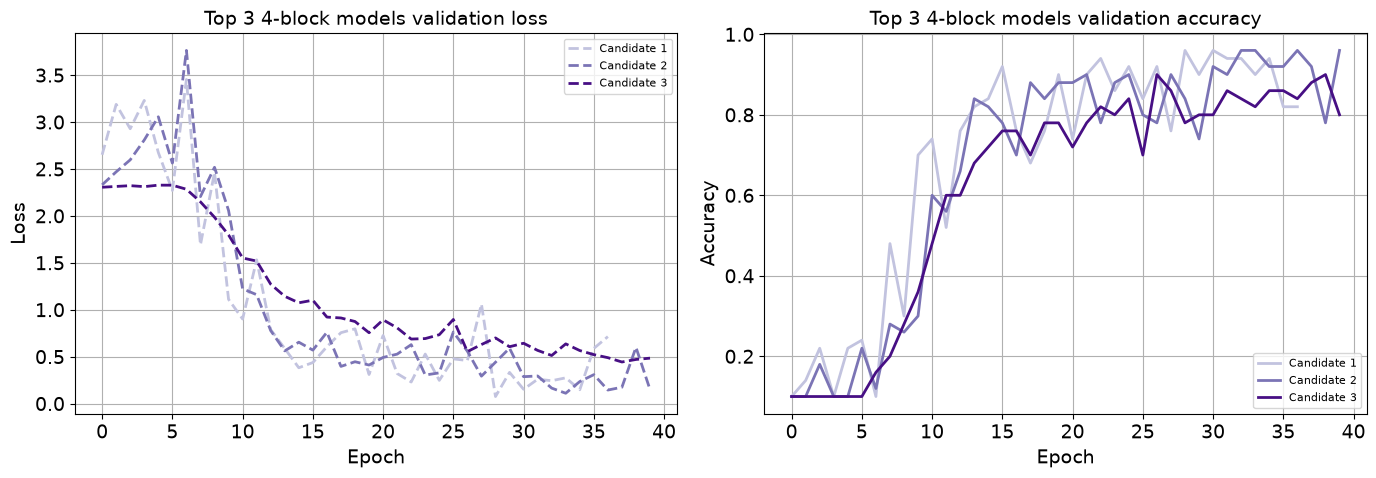

In [16]:
# Plot separate validation loss and accuracy curves for the saved/top 3 four-block models.
# Show validation loss and accuracy side by side for each candidate.
colors = plt.cm.Purples(np.linspace(0.35, 0.95, len(all_histories)))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, history in enumerate(all_histories, 1):
    epochs = np.arange(len(history.history["val_accuracy"]))
    color = colors[i - 1]
    axes[0].plot(
        epochs,
        history.history["val_loss"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
        linestyle="--",
    )
    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        label=f"Candidate {i}",
        color=color,
        linewidth=2,
    )

axes[0].set_title("Top 3 4-block models validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].grid(True)

axes[1].set_title("Top 3 4-block models validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(True)

fig.tight_layout()
fig.savefig(
    ARTIFACTS_DIR / "four_block_model_validation_metrics.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [17]:
# Load the best saved history from each full-size tuning run.
def load_best_saved_history(folder):
    history_paths = sorted(folder.glob("*_history.json"))
    if not history_paths:
        raise FileNotFoundError(f"No saved history JSON files found in {folder}")

    histories = [(path, load_history(path)) for path in history_paths]
    return max(histories, key=lambda item: max(item[1].history["val_accuracy"]))


best_full_size_history_path, best_full_size_history = load_best_saved_history(
    FULL_TUNING_DIR
)
best_four_block_history_path, best_four_block_history = load_best_saved_history(
    FOUR_BLOCK_TUNING_DIR
)

print(
    "Best full-size history:",
    best_full_size_history_path.name,
    f"(val_accuracy={max(best_full_size_history.history['val_accuracy']):.4f})",
)
print(
    "Best four-block history:",
    best_four_block_history_path.name,
    f"(val_accuracy={max(best_four_block_history.history['val_accuracy']):.4f})",
)

Best full-size history: candidate_full_1_history.json (val_accuracy=0.9600)
Best four-block history: candidate_four_block_1_history.json (val_accuracy=0.9600)


In [18]:
# Compare only the final full-size tuning candidates and the dedicated four-block tuning
# candidates. The earlier reduced-resolution screening stage is excluded from this final table.
all_model_results = []
seen_models = set()
# Add the full-size tuning candidates.
for i, model, val_acc in trained_full_models:
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    y_true = X_test_full.classes
    y_pred = np.argmax(model.predict(X_test_full, verbose=0), axis=1)
    history_path = FULL_TUNING_DIR / f"candidate_full_{i}_history.json"
    history = load_history(history_path)
    best_epoch = int(np.argmax(history.history["val_accuracy"]) + 1)
    row = {
        "model": f"full_tuning_candidate_{i}",
        "search_stage": "full_tuning",
        "val_accuracy": val_acc,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "best_epoch": best_epoch,
    }
    if row["model"] not in seen_models:
        seen_models.add(row["model"])
        all_model_results.append(row)
        print(
            f"Full-tuning candidate {i}: test_accuracy={test_accuracy:.4f}, precision={row['precision_macro']:.4f}, recall={row['recall_macro']:.4f}, f1={row['f1_macro']:.4f}"
        )

# Add the dedicated four-block tuning candidates.
for i, model, val_acc in trained_four_block_models:
    test_loss, test_accuracy = model.evaluate(X_test_full, verbose=0)
    y_true = X_test_full.classes
    y_pred = np.argmax(model.predict(X_test_full, verbose=0), axis=1)
    history_path = FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}_history.json"
    history = load_history(history_path)
    best_epoch = int(np.argmax(history.history["val_accuracy"]) + 1)
    row = {
        "model": f"four_block_tuning_candidate_{i}",
        "search_stage": "four_block_tuning",
        "val_accuracy": val_acc,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "best_epoch": best_epoch,
    }
    if row["model"] not in seen_models:
        seen_models.add(row["model"])
        all_model_results.append(row)
        print(
            f"Four-block tuning candidate {i}: test_accuracy={test_accuracy:.4f}, precision={row['precision_macro']:.4f}, recall={row['recall_macro']:.4f}, f1={row['f1_macro']:.4f}"
        )

comparison_df = pd.DataFrame(all_model_results).sort_values(
    by="test_accuracy", ascending=False, ignore_index=True
)

comparison_df

Full-tuning candidate 1: test_accuracy=0.9800, precision=0.9833, recall=0.9800, f1=0.9798
Full-tuning candidate 2: test_accuracy=0.8000, precision=0.8437, recall=0.8000, f1=0.7807
Full-tuning candidate 3: test_accuracy=0.7000, precision=0.7558, recall=0.7000, f1=0.6641
Four-block tuning candidate 1: test_accuracy=0.9400, precision=0.9548, recall=0.9400, f1=0.9381
Four-block tuning candidate 2: test_accuracy=0.9600, precision=0.9667, recall=0.9600, f1=0.9596
Four-block tuning candidate 3: test_accuracy=0.8400, precision=0.8889, recall=0.8400, f1=0.8379


,model,search_stage,val_accuracy,test_loss,test_accuracy,precision_macro,recall_macro,f1_macro,best_epoch
0,full_tuning_candidate_1,full_tuning,0.96,0.097321,0.98,0.983333,0.98,0.979798,49
1,four_block_tuning_candidate_2,four_block_tuning,0.96,0.122981,0.96,0.966667,0.96,0.959596,33
2,four_block_tuning_candidate_1,four_block_tuning,0.96,0.292913,0.94,0.954762,0.94,0.938131,29
3,four_block_tuning_candidate_3,four_block_tuning,0.90,0.539455,0.84,0.888889,0.84,0.837915,27
4,full_tuning_candidate_2,full_tuning,0.88,0.577569,0.80,0.843651,0.80,0.780664,47
5,full_tuning_candidate_3,full_tuning,0.84,0.883603,0.70,0.755833,0.70,0.664118,40


In [19]:
# Select CNN_A from both full-size and four-block tuning candidates, and save the
# chosen model paired with its own saved training history.
cnn_a_candidates = [
    (i, model, val_accuracy, FULL_TUNING_DIR / f"candidate_full_{i}_history.json")
    for i, model, val_accuracy in trained_full_models
] + [
    (
        i,
        model,
        val_accuracy,
        FOUR_BLOCK_TUNING_DIR / f"candidate_four_block_{i}_history.json",
    )
    for i, model, val_accuracy in trained_four_block_models
]

if not cnn_a_candidates:
    raise ValueError(
        "No full-size or four-block tuning candidates are available to select CNN_A."
    )

cnn_a_id, cnn_a, cnn_a_val_accuracy, cnn_a_history_path = max(
    cnn_a_candidates, key=lambda candidate: candidate[2]
)
cnn_a_history = load_history(cnn_a_history_path)
cnn_a.save(str(CNN_A_MODEL_PATH))
save_history(cnn_a_history, NOTEBOOK_DIR / "CNN_A_history.json")
print(
    f"Selected CNN_A candidate {cnn_a_id} with validation accuracy "
    f"{cnn_a_val_accuracy:.4f}; history loaded from {cnn_a_history_path.name}."
)
# Save the best full-size model architecture as an image for reporting.
try:
    tf.keras.utils.plot_model(
        cnn_a,
        to_file=str(ARTIFACTS_DIR / "cnn_a_architecture.png"),
        show_shapes=True,
        show_dtype=False,
        show_layer_names=True,
        rankdir="TB",
        expand_nested=False,
        dpi=150,
    )
    print(
        f"Saved best full-size model architecture to {ARTIFACTS_DIR / 'cnn_a_architecture.png'}"
    )
except Exception as e:
    print(f"Could not save best full-size model architecture: {e}")

Selected CNN_A candidate 1 with validation accuracy 0.9600; history loaded from candidate_full_1_history.json.
Saved best full-size model architecture to /Users/lauryn/Documents/advanced_ml/cnn/artifacts/cnn_a_architecture.png


## Part 1c: Conclusion

Full-resolution candidate 1 from the initial tuning was selected as CNN A, with validation accuracy of 0.96, test accuracy of 0.98, and macro F1 score of 0.980. The strongest four-block candidate attained test accuracy of 0.96. Although this result indicates that the deeper architecture was competitive, it did not outperform candidate 1 in the final comparison. The selected model and its training history were retained for use in Part 2. Additionally, some alternative candidates reached their best validation performance in fewer epochs, however, candidate 1 achieved the strongest overall test performance.


# Part 2: Transfer Learning

Part 2 evaluates transfer learning on a separate 10-class bird-image dataset. The classifier of the selected CNN A is replaced with a task-specific classification head. Two strategies are compared: training the new head while freezing the convolutional base, and training the head while fine-tuning the final CNN block. 

In [20]:
# Define the data generators for the bird image dataset.
# The selected CNN was trained on the full-resolution input size used in Part 1,
# so the Part 2 generators must match the saved model input shape.
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest",
)
valid_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
test_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)

X_train = train_gen.flow_from_directory(
    str(P2_TRAIN_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=True,
)

X_valid = valid_gen.flow_from_directory(
    str(P2_VALID_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False,
)

X_test = test_gen.flow_from_directory(
    str(P2_TEST_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False,
)

Found 1561 images belonging to 10 classes.


Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.


In [21]:
# Check whether the class distribution is balanced across the dataset.

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [
    ("train", P2_TRAIN_DIR),
    ("valid", P2_VALID_DIR),
    ("test", P2_TEST_DIR),
]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob("*")))
            if split_name == "train":
                train_counts[class_dir.name] = count
            elif split_name == "valid":
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print("Train class counts:", dict(train_counts))
print("Validation class counts:", dict(valid_counts))
print("Test class counts:", dict(test_counts))

# Compute a class-weight dictionary based on the imbalanced training split.
# This down-weights majority classes without duplicating images or altering the
# original dataset distribution.
class_indices = X_train.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)

for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print("Class weights:", class_weights)

Train class counts: {'ANTILLEAN EUPHONIA': 139, 'BANDED STILT': 153, 'BLACK AND YELLOW BROADBILL': 142, 'CRESTED COUA': 152, 'EASTERN GOLDEN WEAVER': 152, 'FLAME TANAGER': 177, 'GOLDEN BOWER BIRD': 140, 'MAGPIE GOOSE': 142, 'WILD TURKEY': 153, 'WOOD THRUSH': 211}
Validation class counts: {'ANTILLEAN EUPHONIA': 5, 'BANDED STILT': 5, 'BLACK AND YELLOW BROADBILL': 5, 'CRESTED COUA': 5, 'EASTERN GOLDEN WEAVER': 5, 'FLAME TANAGER': 5, 'GOLDEN BOWER BIRD': 5, 'MAGPIE GOOSE': 5, 'WILD TURKEY': 5, 'WOOD THRUSH': 5}
Test class counts: {'ANTILLEAN EUPHONIA': 5, 'BANDED STILT': 5, 'BLACK AND YELLOW BROADBILL': 5, 'CRESTED COUA': 5, 'EASTERN GOLDEN WEAVER': 5, 'FLAME TANAGER': 5, 'GOLDEN BOWER BIRD': 5, 'MAGPIE GOOSE': 5, 'WILD TURKEY': 5, 'WOOD THRUSH': 5}
Class weights: {0: 1.123021582733813, 1: 1.0202614379084967, 2: 1.0992957746478873, 3: 1.0269736842105264, 4: 1.0269736842105264, 5: 0.8819209039548023, 6: 1.115, 7: 1.0992957746478873, 8: 1.0202614379084967, 9: 0.7398104265402844}


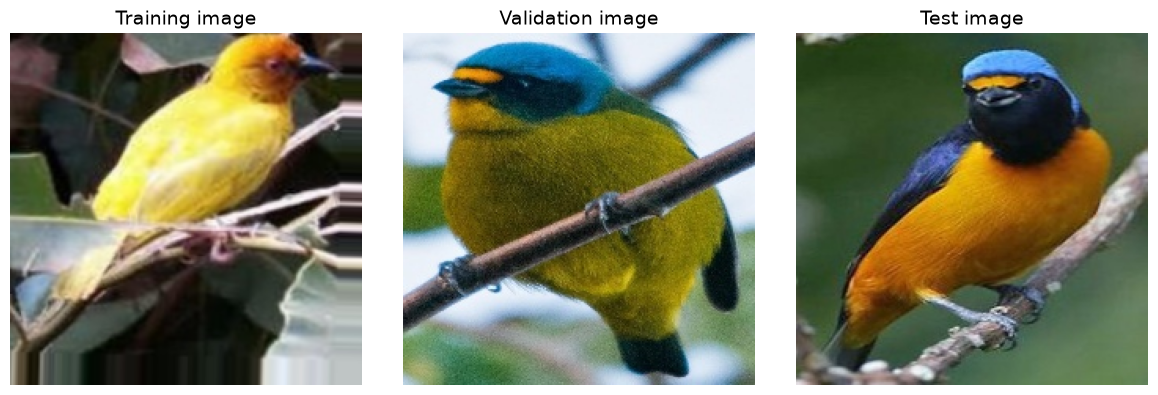

In [22]:
# Visualise a few representative examples from each split.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sample_train = X_train[0][0][0]
sample_valid = X_valid[0][0][0]
sample_test = X_test[0][0][0]

axes[0].imshow(sample_train)
axes[0].set_title("Training image")
axes[0].axis("off")

axes[1].imshow(sample_valid)
axes[1].set_title("Validation image")
axes[1].axis("off")

axes[2].imshow(sample_test)
axes[2].set_title("Test image")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Load the saved CNN from the previous stage and inspect its structure.
base_model = tf.keras.models.load_model(str(CNN_A_MODEL_PATH))
base_model.summary()

print(f"Loaded base model from: {CNN_A_MODEL_PATH}")
print(f"Input shape: {base_model.input_shape}")
print(f"Output shape: {base_model.output_shape}")

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 112, 112, 128)  │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 28, 28, 32)     │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,184,704 (4.52 MB)

 Trainable params: 394,666 (1.51 MB)

 Non-trainable params: 704 (2.75 KB)

 Optimizer params: 789,334 (3.01 MB)

Loaded base model from: /Users/lauryn/Documents/advanced_ml/cnn/CNN_A.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 10)


In [24]:
tf.keras.backend.clear_session()


# Function to build a transfer learning model using the saved base model as a feature extractor.
def build_transfer_model(model_path, fine_tune=False):
    backbone = tf.keras.models.load_model(model_path)
    backbone.trainable = False

    # Use the feature tensor immediately before the original classification head.
    # This is the correct transfer-learning feature space, not the already-specialized logits.
    feature = backbone.get_layer("global_average_pooling2d_4").output
    x = tf.keras.layers.Dense(256, activation="relu")(feature)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax")(x)
    model = tf.keras.Model(inputs=backbone.input, outputs=outputs)

    if fine_tune:
        backbone.trainable = True
        for layer in backbone.layers[:-4]:
            layer.trainable = False
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
    else:
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )
    return model

## Part 2a: Head-Only Transfer Learning

For the head-only approach, the convolutional base of CNN A is frozen and only the new classification head is trained on the Part 2 classes. This experiment assesses whether the learned feature representations are sufficiently transferable to support classification of the target classes without updating the feature extractor.


In [25]:
# Train the head-only transfer model while the base CNN remains frozen.
if (NOTEBOOK_DIR / "TL_head.keras").exists() and (
    NOTEBOOK_DIR / "TL_head_history.json"
).exists():
    print("Loading the saved head-only transfer-learning model from disk...")

    head_only_transfer_model = tf.keras.models.load_model(
        str(NOTEBOOK_DIR / "TL_head.keras")
    )

    head_only_transfer_model.summary()
    head_only_history = load_history(NOTEBOOK_DIR / "TL_head_history.json")
else:
    head_only_transfer_model = build_transfer_model(
        str(CNN_A_MODEL_PATH), fine_tune=False
    )
    print("\nBase transfer-learning variant created from the saved base model.")
    head_only_transfer_model.summary()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
        )
    ]

    head_only_history = head_only_transfer_model.fit(
        X_train,
        validation_data=X_valid,
        epochs=80,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1,
    )

    # Save the standard transfer-learning checkpoint and history.
    TL_MODEL_PATH = NOTEBOOK_DIR / "TL_head.keras"
    head_only_transfer_model.save(str(TL_MODEL_PATH))
    save_history(head_only_history, NOTEBOOK_DIR / "TL_head_history.json")
    print(f"Standard transfer-learned model saved to: {TL_MODEL_PATH}")

print("Final train accuracy:", head_only_history.history["accuracy"][-1])
print("Final validation accuracy:", head_only_history.history["val_accuracy"][-1])
best_epoch = np.argmax(head_only_history.history["val_accuracy"]) + 1
print(f"Best epoch: {best_epoch}")

Loading the saved head-only transfer-learning model from disk...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 112, 112, 128)  │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 28, 28, 32)     │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,664 (1.62 MB)

 Trainable params: 11,018 (43.04 KB)

 Non-trainable params: 392,608 (1.50 MB)

 Optimizer params: 22,038 (86.09 KB)

Final train accuracy: 0.7296604514122009
Final validation accuracy: 0.6399999856948853
Best epoch: 16


## Part 2b: Fine-Tuned Transfer Learning

For the fine-tuned approach, the new classification head and final CNN block are trained, while the earlier convolutional layers remain frozen. This strategy permits adaptation of higher-level feature representations to the classes.


In [26]:
# Fine-tune a slightly deeper portion of the base model from an independent copy
# of the base CNN rather than continuing from the head-only transfer model. This keeps
# the two transfer-learning strategies distinct and directly comparable.
if (NOTEBOOK_DIR / "TL_deep.keras").exists() and (
    NOTEBOOK_DIR / "TL_deep_history.json"
).exists():
    print("Loading the saved deeper fine-tuned transfer-learning model from disk...")
    deep_transfer_model = tf.keras.models.load_model(
        str(NOTEBOOK_DIR / "TL_deep.keras")
    )
    deep_transfer_model.summary()
    deep_history = load_history(NOTEBOOK_DIR / "TL_deep_history.json")
else:

    deep_transfer_model = build_transfer_model(str(CNN_A_MODEL_PATH), fine_tune=True)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
        )
    ]
    deep_history = deep_transfer_model.fit(
        X_train,
        validation_data=X_valid,
        epochs=80,
        callbacks=callbacks,
        class_weight=class_weights,
        verbose=1,
    )

    # Save the deeper fine-tuned transfer-learning checkpoint and history.
    DEEP_TL_MODEL_PATH = NOTEBOOK_DIR / "TL_deep.keras"
    deep_transfer_model.save(str(DEEP_TL_MODEL_PATH))
    save_history(deep_history, NOTEBOOK_DIR / "TL_deep_history.json")

    print(f"Deeper fine-tuned transfer-learned model saved to: {DEEP_TL_MODEL_PATH}")

print("Final train accuracy:", deep_history.history["accuracy"][-1])
print("Final validation accuracy:", deep_history.history["val_accuracy"][-1])
best_epoch = np.argmax(deep_history.history["val_accuracy"]) + 1
print(f"Best epoch: {best_epoch}")

Loading the saved deeper fine-tuned transfer-learning model from disk...


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 112, 112, 128)  │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 28, 28, 32)     │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,664 (1.62 MB)

 Trainable params: 11,018 (43.04 KB)

 Non-trainable params: 392,608 (1.50 MB)

 Optimizer params: 22,038 (86.09 KB)

Final train accuracy: 0.5618193745613098
Final validation accuracy: 0.5400000214576721
Best epoch: 76


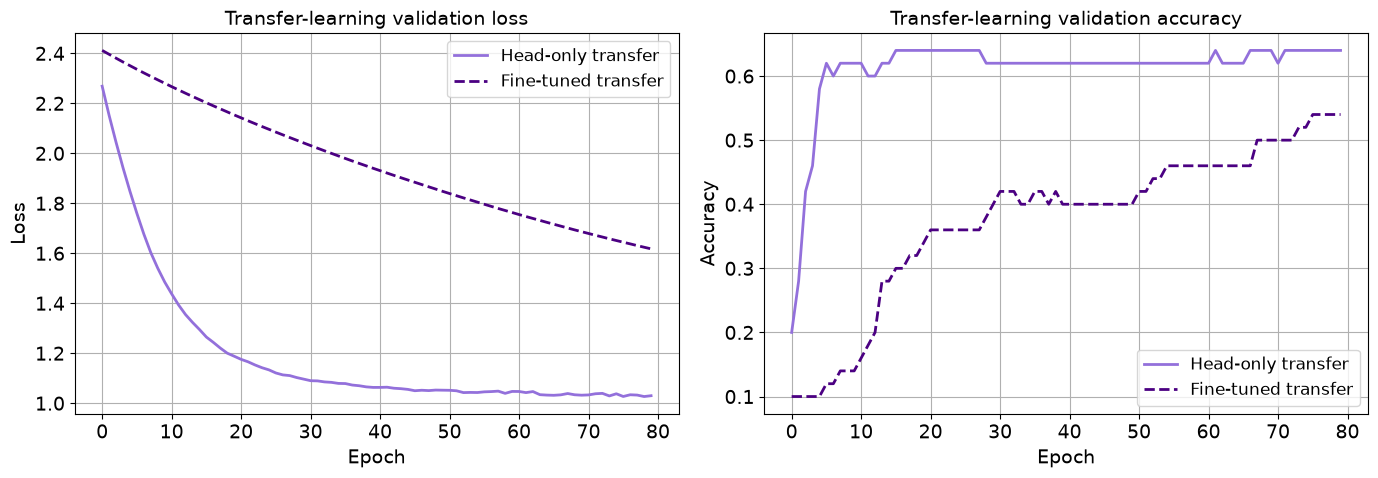

In [27]:
# Compare the validation loss and accuracy curves for the head-only and fine-tuned transfer models.
# Each metric is plotted in its own figure to keep the curves easy to interpret.
# Show transfer-learning validation loss and accuracy side by side.
head_epochs = np.arange(len(head_only_history.history["val_accuracy"]))
deep_epochs = np.arange(len(deep_history.history["val_accuracy"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    head_epochs,
    head_only_history.history["val_loss"],
    label="Head-only transfer",
    color="mediumpurple",
    linewidth=2,
)
axes[0].plot(
    deep_epochs,
    deep_history.history["val_loss"],
    label="Fine-tuned transfer",
    color="indigo",
    linewidth=2,
    linestyle="--",
)
axes[0].set_title("Transfer-learning validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(loc="upper right")
axes[0].grid(True)

axes[1].plot(
    head_epochs,
    head_only_history.history["val_accuracy"],
    label="Head-only transfer",
    color="mediumpurple",
    linewidth=2,
)
axes[1].plot(
    deep_epochs,
    deep_history.history["val_accuracy"],
    label="Fine-tuned transfer",
    color="indigo",
    linewidth=2,
    linestyle="--",
)
axes[1].set_title("Transfer-learning validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(loc="lower right")
axes[1].grid(True)

fig.tight_layout()
fig.savefig(
    ARTIFACTS_DIR / "transfer_learning_validation_metrics.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [28]:
# Evaluate both transfer-learning variants on the same held-out test set.
base_test_loss, base_test_acc = head_only_transfer_model.evaluate(X_test, verbose=0)
deep_test_loss, deep_test_acc = deep_transfer_model.evaluate(X_test, verbose=0)

# Generate predictions so that class-averaged metrics can be computed.
y_true = X_test.classes
head_predictions = np.argmax(
    head_only_transfer_model.predict(X_test, verbose=0), axis=1
)
deep_predictions = np.argmax(
    deep_transfer_model.predict(X_test, verbose=0), axis=1
)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def transfer_metrics(name, history, predictions, test_loss):
    return {
        "approach": name,
        "val_accuracy": max(history.history["val_accuracy"]),
        "val_loss": min(history.history["val_loss"]),
        "test_loss": test_loss,
        "test_accuracy": accuracy_score(y_true, predictions),
        "test_precision_macro": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "test_recall_macro": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "test_f1_macro": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "best_epoch": int(np.argmax(history.history["val_accuracy"]) + 1),
    }

comparison_df = pd.DataFrame(
    [
        transfer_metrics(
            "head_only_transfer",
            head_only_history,
            head_predictions,
            base_test_loss,
        ),
        transfer_metrics(
            "deeper_fine_tuning",
            deep_history,
            deep_predictions,
            deep_test_loss,
        ),
    ]
).sort_values("test_accuracy", ascending=False, ignore_index=True)

# Save the transfer variant with the higher test accuracy as CNN B.
if deep_test_acc > base_test_acc:
    final_transfer_model = deep_transfer_model
    final_transfer_history = deep_history
else:
    final_transfer_model = head_only_transfer_model
    final_transfer_history = head_only_history

final_transfer_model.save(str(CNN_B_MODEL_PATH))
save_history(final_transfer_history, NOTEBOOK_DIR / "CNN_B_history.json")

comparison_df

,approach,val_accuracy,val_loss,test_loss,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,best_epoch
0,head_only_transfer,0.64,1.026652,1.275445,0.68,0.754524,0.68,0.668506,79
1,deeper_fine_tuning,0.54,1.617619,1.662290,0.52,0.474286,0.52,0.479524,80


## Part 2c: Conclusion

The results indicate that CNN A provided a partially effective feature extractor for CNN B. With the convolutional base frozen, the transferred model achieved 0.68 test accuracy and a test loss of 1.275. Fine-tuning the final CNN block produced lower test accuracy (0.52) and a higher test loss (1.662). The head-only model was therefore selected as CNN B. Its macro precision, recall, and F1 score were 0.755, 0.680, and 0.669, respectively. These results show that the features learned by CNN A did transfer to CNN B, but performance was not sufficiently high to say that the transfer learning was successful.


In [ ]:
# Final CNN A and CNN B comparison using multiple classification metrics.
# These models are evaluated on their respective dataset stages, so the table is a
# benchmark summary rather than a direct same-dataset head-to-head comparison.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

cnn_a_model = tf.keras.models.load_model(str(CNN_A_MODEL_PATH))
cnn_b_model = tf.keras.models.load_model(str(CNN_B_MODEL_PATH))

cnn_a_loss, _ = cnn_a_model.evaluate(X_test_full, verbose=0)
cnn_b_loss, _ = cnn_b_model.evaluate(X_test, verbose=0)

# Loaded models do not retain their fit history, so read best epochs from saved histories.
cnn_a_history = load_history(NOTEBOOK_DIR / "CNN_A_history.json")
cnn_a_best_epoch = int(np.argmax(cnn_a_history.history["val_accuracy"]) + 1)
cnn_b_history = load_history(NOTEBOOK_DIR / "CNN_B_history.json")
cnn_b_best_epoch = int(np.argmax(cnn_b_history.history["val_accuracy"]) + 1)

y_true_a = X_test_full.classes
y_pred_a = np.argmax(cnn_a_model.predict(X_test_full, verbose=0), axis=1)

y_true_b = X_test.classes
y_pred_b = np.argmax(cnn_b_model.predict(X_test, verbose=0), axis=1)

final_comparison_df = pd.DataFrame(
    [
        {
            "model": "CNN A",
            "dataset": "Part 1",
            "accuracy": accuracy_score(y_true_a, y_pred_a),
            "precision_macro": precision_score(
                y_true_a, y_pred_a, average="macro", zero_division=0
            ),
            "recall_macro": recall_score(
                y_true_a, y_pred_a, average="macro", zero_division=0
            ),
            "f1_macro": f1_score(y_true_a, y_pred_a, average="macro", zero_division=0),
            "test_loss": cnn_a_loss,
            "approx_trainable_params": cnn_a_model.count_params(),
            "best_epoch": cnn_a_best_epoch,
        },
        {
            "model": "CNN B",
            "dataset": "Part 2",
            "accuracy": accuracy_score(y_true_b, y_pred_b),
            "precision_macro": precision_score(
                y_true_b, y_pred_b, average="macro", zero_division=0
            ),
            "recall_macro": recall_score(
                y_true_b, y_pred_b, average="macro", zero_division=0
            ),
            "f1_macro": f1_score(y_true_b, y_pred_b, average="macro", zero_division=0),
            "test_loss": cnn_b_loss,
            "approx_trainable_params": cnn_b_model.count_params(),
            "best_epoch": cnn_b_best_epoch,
        },
    ]
).sort_values("accuracy", ascending=False, ignore_index=True)

final_comparison_df

## Final Conclusion

The staged architecture search selected full-resolution candidate 1 as CNN A for the
Part 1 classification task. This model achieved validation accuracy of 0.96 and test
accuracy of 0.98. In Part 2, the head-only transfer model achieved 0.68 test accuracy,
while the variant that fine-tuned the final CNN block achieved 0.52. Accordingly,
head-only training was the stronger of the two transfer-learning strategies evaluated.
CNN A therefore provided a useful, but only partially effective, feature extractor for
CNN B.

#### Efficiency Constraints

CNN A reached peak validation accuracy at epoch 49. The head-only CNN B reached its
peak validation accuracy at epoch 16, while the fine-tuned variant peaked at epoch 76.
Thus, by this epoch-based measure, head-only transfer reached its best validation
accuracy sooner than CNN A. It also updated only the new classification head while
keeping the CNN A feature extractor frozen, reducing the number of trainable parameters
and the optimization work per step. However, the models were trained on different
datasets, and wall-clock training times were not recorded; these results therefore do
not establish lower total runtime for CNN B.